# Прогнозирование сроков доставки

Регрессия на открытых данных Olist (электронная коммерция, **не железнодорожные перевозки**). Признаки доступны при оформлении заказа; фактическое время используется только как целевая переменная.

## Данные

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Path('results').mkdir(exist_ok=True)
PRIVATE_ROOT = Path.home() / 'ML_private_datasets'
data = PRIVATE_ROOT / 'olist'
orders = pd.read_csv(data / 'olist_orders_dataset.csv', parse_dates=['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date'])
customers = pd.read_csv(data / 'olist_customers_dataset.csv', usecols=['customer_id', 'customer_state'])
items = pd.read_csv(data / 'olist_order_items_dataset.csv', usecols=['order_id', 'seller_id', 'price', 'freight_value'])
sellers = pd.read_csv(data / 'olist_sellers_dataset.csv', usecols=['seller_id', 'seller_state'])
print('Заказы:', len(orders))

Заказы: 99441


## Объединение и признаки

In [2]:
item_info = items.merge(sellers, on='seller_id', how='left')
order_items = item_info.groupby('order_id').agg(
    item_count=('price', 'size'),
    total_price=('price', 'sum'),
    total_freight=('freight_value', 'sum'),
    sellers_count=('seller_id', 'nunique'),
    seller_state=('seller_state', 'first')
)

work = orders[orders.order_status == 'delivered'].copy()
work = work.merge(customers, on='customer_id', how='left')
work = work.merge(order_items, on='order_id', how='left')
work['delivery_days'] = (work.order_delivered_customer_date - work.order_purchase_timestamp).dt.total_seconds() / 86400
work['estimated_days'] = (work.order_estimated_delivery_date - work.order_purchase_timestamp).dt.total_seconds() / 86400
work = work.dropna(subset=['order_purchase_timestamp', 'delivery_days', 'estimated_days'])
work = work[(work.delivery_days >= 0) & (work.estimated_days > 0)].copy()
work['purchase_month'] = work.order_purchase_timestamp.dt.month
work['purchase_weekday'] = work.order_purchase_timestamp.dt.dayofweek
work['purchase_year'] = work.order_purchase_timestamp.dt.year
print('Заказов после обработки:', len(work))

Заказов после обработки: 96470


## Разделение по времени

In [3]:
num_cols = ['estimated_days', 'item_count', 'total_price', 'total_freight',
            'sellers_count', 'purchase_month', 'purchase_weekday', 'purchase_year']
cat_cols = ['customer_state', 'seller_state']
features = num_cols + cat_cols

work = work.sort_values('order_purchase_timestamp')
n = len(work)
train, valid, test = work.iloc[:int(n*.64)], work.iloc[int(n*.64):int(n*.80)], work.iloc[int(n*.80):]
X_train, y_train = train[features], train.delivery_days
X_val, y_val = valid[features], valid.delivery_days
X_test, y_test = test[features], test.delivery_days

print('Train:', len(train), '| Validation:', len(valid), '| Test:', len(test))

Train: 61740 | Validation: 15436 | Test: 19294


## Сравнение моделей

Ridge MAE: 6.782
Decision Tree MAE: 7.153
Random Forest MAE: 7.052
Gradient Boosting MAE: 6.931


,model,validation_MAE
0,Ridge,6.782
3,Gradient Boosting,6.931
2,Random Forest,7.052
1,Decision Tree,7.153


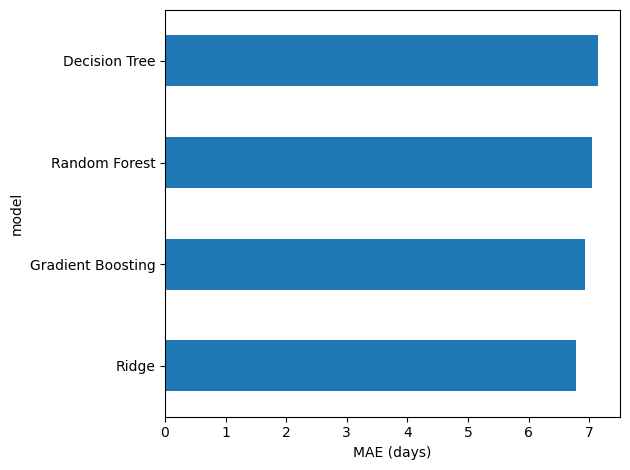

In [6]:
preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

models = {
    'Ridge': Ridge(alpha=10),
    'Decision Tree': DecisionTreeRegressor(max_depth=12, min_samples_leaf=12, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=70, max_depth=16, min_samples_leaf=5, n_jobs=-1, random_state=42),
    'Gradient Boosting': HistGradientBoostingRegressor(max_iter=120, l2_regularization=1, random_state=42)
}

scores = []
for name, algorithm in models.items():
    model = make_pipeline(preprocess, algorithm)
    model.fit(X_train, y_train)
    pred = np.maximum(model.predict(X_val), 0)
    scores.append([name, mean_absolute_error(y_val, pred)])
    print(name, 'MAE:', round(scores[-1][1], 3))

results = pd.DataFrame(scores, columns=['model', 'validation_MAE']).sort_values('validation_MAE')
display(results.round(3))
results.to_csv('results/validation_results.csv', index=False)
results.plot.barh(x='model', y='validation_MAE', legend=False)
plt.xlabel('MAE (days)')
plt.tight_layout()
plt.savefig('results/validation_mae.png', dpi=150)
plt.show()

## Итоговая проверка

,model,MAE,RMSE,R2
0,Median baseline,4.963,6.381,-0.170
1,Promised delivery,13.135,15.918,-6.278
2,Ridge,6.450,7.791,-0.743


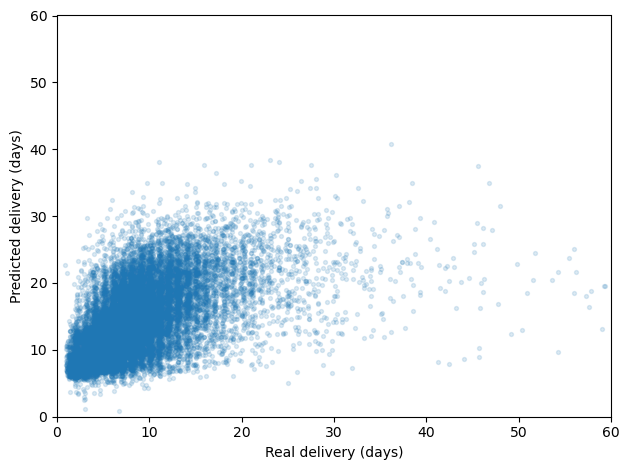

In [7]:
best_name = results.iloc[0]['model']
model = make_pipeline(preprocess, models[best_name])
X_all = pd.concat([X_train, X_val])
y_all = pd.concat([y_train, y_val])
model.fit(X_all, y_all)
pred = np.maximum(model.predict(X_test), 0)

rows = []
for name, values in {
    'Median baseline': np.full(len(y_test), y_all.median()),
    'Promised delivery': X_test.estimated_days.to_numpy(),
    best_name: pred
}.items():
    rows.append([name, mean_absolute_error(y_test, values),
                 np.sqrt(mean_squared_error(y_test, values)), r2_score(y_test, values)])

final = pd.DataFrame(rows, columns=['model', 'MAE', 'RMSE', 'R2'])
display(final.round(3))
final.to_csv('results/test_results.csv', index=False)

plt.scatter(y_test, pred, alpha=0.15, s=8)
plt.xlabel('Real delivery (days)')
plt.ylabel('Predicted delivery (days)')
plt.xlim(0, 60)
plt.ylim(0, 60)
plt.tight_layout()
plt.savefig('results/test_predictions.png', dpi=150)
plt.show()

## Вывод

Выбранная модель определяется по validation MAE. Сравнение с медианным прогнозом и обещанным сроком выполняется на отдельной тестовой выборке. Достоверность результатов ограничена выбранными признаками и отличиями электронной коммерции от железнодорожной логистики.